In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from src.models.classifier import SignalClassifier

print("All imports successful!")

All imports successful!


In [2]:
with open('../data/processed/ticker_list.txt', 'r') as f:
    all_tickers = [line.strip() for line in f.readlines()]

bank_tickers = ['NABIL', 'NICA', 'HBL', 'ADBL', 'EBL', 
                'SCB', 'SBI', 'SANIMA', 'GBIME', 'NBL',
                'NIMB', 'CZBIL', 'MBL', 'PCBL', 'NMB',
                'PRVU', 'SRBL', 'LXBL', 'KBL']

dfs = []
for ticker in bank_tickers:
    try:
        df = pd.read_csv(f'../data/processed/{ticker}_features.csv')
        dfs.append(df)
    except:
        pass

data = pd.concat(dfs, ignore_index=True)
print(f"Total rows: {len(data)}")
print(f"Stocks loaded: {data['Ticker'].nunique()}")
print(f"\nLabel distribution:")
print(data['Label'].value_counts())
print(f"\nDate range: {data['Date'].min()} to {data['Date'].max()}")

Total rows: 3791
Stocks loaded: 17

Label distribution:
Label
1    2416
0     706
2     669
Name: count, dtype: int64

Date range: 2025-06-25 to 2026-06-24


In [ ]:
drop_cols = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume',
             'Trades', 'Turnover', 'Ticker', 'Label', 'Future_Return', 'Sector']
feature_cols = [c for c in data.columns if c not in drop_cols]

data = data.dropna(subset=feature_cols + ['Label'])
X = data[feature_cols]
y = data['Label']

print(f"Features: {feature_cols}")
print(f"Total features: {len(feature_cols)}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain: {len(X_train)} rows")
print(f"Test:  {len(X_test)} rows")

# Load saved model
clf = SignalClassifier.load('../data/models/Commercial_Banks_model.pkl')
print("\nModel loaded successfully!")
print(f"Model type: {clf.model_type}")

Features: ['SMA_7', 'SMA_21', 'SMA_50', 'EMA_12', 'EMA_26', 'MACD', 'MACD_Signal', 'RSI_14', 'Stoch', 'BB_High', 'BB_Low', 'BB_Width', 'ATR', 'Volume_Change', 'OBV', 'Close_lag_1', 'Return_lag_1', 'Close_lag_3', 'Return_lag_3', 'Close_lag_5', 'Return_lag_5', 'Close_lag_10', 'Return_lag_10']
Total features: 23

Train: 2366 rows
Test:  592 rows

Model loaded successfully!
Model type: lightgbm


  File "c:\projects\nepse_intelligence\env\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\rosha\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 546, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rosha\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1022, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\rosha\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1491, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


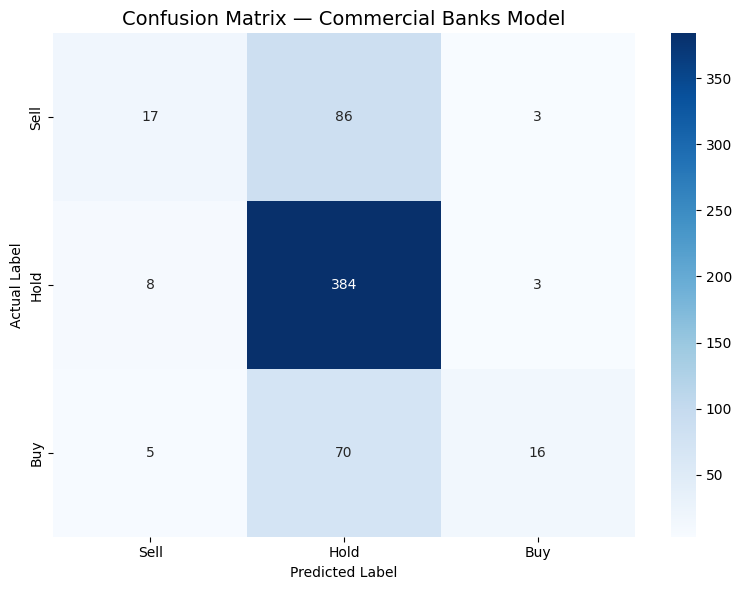


Classification Report:
              precision    recall  f1-score   support

        Sell       0.57      0.16      0.25       106
        Hold       0.71      0.97      0.82       395
         Buy       0.73      0.18      0.28        91

    accuracy                           0.70       592
   macro avg       0.67      0.44      0.45       592
weighted avg       0.69      0.70      0.64       592



In [4]:
preds = clf.model.predict(X_test)
label_names = ['Sell', 'Hold', 'Buy']

# Plot confusion matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names,
            yticklabels=label_names)
plt.title('Confusion Matrix — Commercial Banks Model', fontsize=14)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, preds, target_names=label_names))

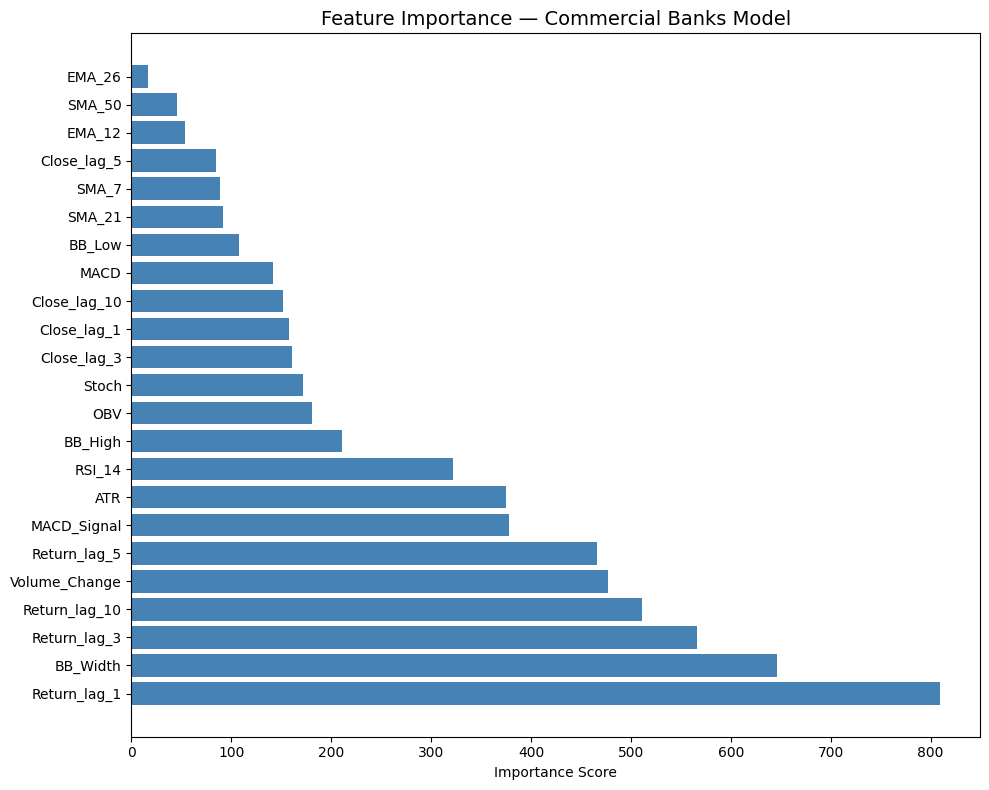


Top 5 most important features:
      Feature  Importance
 Return_lag_1         809
     BB_Width         646
 Return_lag_3         566
Return_lag_10         511
Volume_Change         477


In [7]:
import lightgbm as lgb

# Get feature importance
importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': clf.model.feature_importances_
}).sort_values('Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 8))
plt.barh(importance['Feature'], importance['Importance'], color='steelblue')
plt.title('Feature Importance — Commercial Banks Model', fontsize=14)
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("\nTop 5 most important features:")
print(importance.head(5)[['Feature', 'Importance']].to_string(index=False))

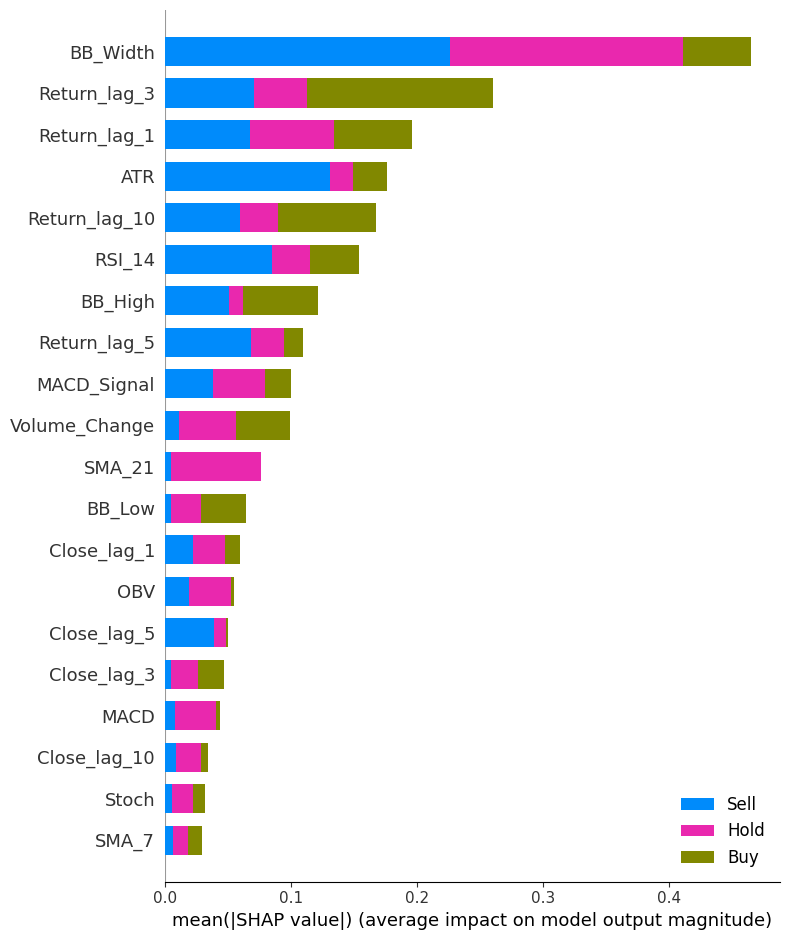

In [6]:
# SHAP explanation for the model
explainer = shap.TreeExplainer(clf.model)
shap_values = explainer.shap_values(X_test)

# Summary plot — shows impact of each feature on predictions
shap.summary_plot(shap_values, X_test, 
                  class_names=['Sell', 'Hold', 'Buy'],
                  feature_names=feature_cols,
                  plot_type='bar')

NABIL Signal: Hold
Confidence: 86.2%
Probabilities: {'Sell': 0.07123007424222173, 'Hold': 0.8623686606900601, 'Buy': 0.06640126506771805}


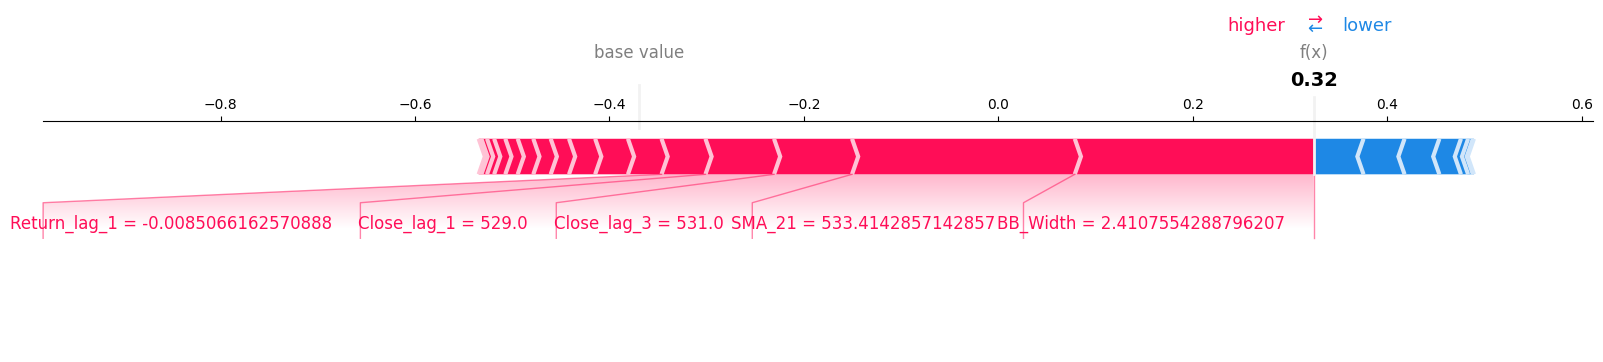

In [8]:
# Explain one prediction for NABIL (latest data point)
nabil = pd.read_csv('../data/processed/NABIL_features.csv')
nabil = nabil.dropna(subset=feature_cols)
latest = nabil[feature_cols].tail(1)

# Get prediction
result = clf.predict(latest)
print(f"NABIL Signal: {result['signal']}")
print(f"Confidence: {result['confidence']*100:.1f}%")
print(f"Probabilities: {result['probabilities']}")

# SHAP force plot for this prediction
shap.initjs()
explainer2 = shap.TreeExplainer(clf.model)
shap_vals = explainer2.shap_values(latest)

# Show which features pushed toward the predicted signal
label_idx = {'Sell': 0, 'Hold': 1, 'Buy': 2}
pred_idx = label_idx[result['signal']]

shap.force_plot(
    explainer2.expected_value[pred_idx],
    shap_vals[pred_idx],
    latest,
    matplotlib=True,
    show=True
)